# 4. Criatura lendária: Tiamat
**Projeto final de Aprendizado de Máquina**

**Autor: Abraham E. G. Contreras**

## Objetivo:
Escolha um conjunto de dados que siga as considerações abaixo e compare o desempenho 
de pelo menos 3 algoritmos/pipelines de aprendizado de máquina (sem contar o baseline). É necessário 
testar pelo menos 100 conjuntos diferentes de hiperparâmetros para cada algoritmo/pipeline escolhido 
utilizando o optuna (sem contar o modelo baseline). A entrega deverá ser realizada em repositório tipo 
git com README que guia o leitor sobre o que é e como navegar no repositório. Este é o projeto final 
da disciplina de Aprendizado de Máquina, logo é esperado que esta seja uma entrega científica que 
fundamenta bem o problema, trazendo resultados e discutindo eles. Se você optar por fazer scripts de 
Python (não é necessário, porém alguns estudantes fazem essa opção), lembre‑se que ainda é necessário 
um relatório científico para acompanhar a entrega (seja em pdf ou notebook Jupyter, jamais em arquivo 
de Word).
## Considerações:
O conjunto de dados deve ter as seguintes características:
• Pelo menos 10 atributos
• Pelo menos 1 target (não há necessidade de mais que 1 target e pode ser um target categórico 
ou numérico, a sua escolha)
• Pelo menos 300 exemplos
• Não pode ser o conjunto de dados utilizado na entrega do Cubo Gelatinoso
• Não utilizar datasets sintéticos ou didáticos como o iris, pinguins, titanic, vinhos, diamantes, 
gorjetas, etc. (alguns exemplos destes datasets didáticos podem ser conferidos aqui
)
## Expectativas:
É esperado que o trabalho siga as boas práticas apresentadas na disciplina, apresente 
resultados de forma gráfica, use seções bem nomeadas e bem divididas no notebook de Jupyter e 
encerre a entrega com uma seção chamada “Conclusões e principais aprendizados”. Não é necessário 
utilizar todas as estratégias e ferramentas discutidas em sala, porém, por se tratar de um projeto final 
da disciplina, é esperado que a entrega seja suficientemente abrangente e detalhada, demonstrando 
o entendimento e a aplicação prática dos conceitos discutidos ao longo da disciplina. Pode utilizar 
estratégias e ferramentas não apresentadas durante a disciplina caso tenha interesse e faça sentido 
dentro do escopo do projeto (desde que saiba explicar como elas funcionam). É recomendado não 
utilizar dados sequencias ou espacialmente autocorrelacionados para esta atividade (séries temporais 
ou dados que contenham latitude e longitude, por exemplo) pois eles exigem um tratamento de dados 
que ainda não foi apresentado no curso da Ilum. O trabalho deve ter uma seção chamada “Descrição 
do uso de IA neste trabalho” detalhando como foi a interação com ferramentas de IA para a construção 
dos textos e códigos.

## Introdução

O objetivo deste projeto é desenvolver, otimizar e comparar  diversos modelos de aprendizado de máquina supervisionado para a tarefa de classificação binária de respostas biológicas de moléculas (``BioResponse``). O conjunto de dados selecionado está disponível no OpenML sob o ID 4134 e compreende 3.751 instâncias descritas por 1.776 atributos numéricos (descritores moleculares estruturais normalizados). 
O desafio encontra-se na **alta dimensionalidade** além da complexidade relacionada às relações moleculares, tornando importante o uso de estratégias robustas de validação cruzada para evitar **sobreajuste (overfitting)** e **otimização de hiperparâmetros** via Optuna.

## 2. Fundamentação Teórica

### 2.1. Aprendizado de máquina supervisionado

O aprendizado de máquina (*Machine Learning*) é uma área da computação que desenvolve algoritmos capazes de identificar padrões em dados e utilizar esses padrões para realizar previsões. No aprendizado supervisionado, o modelo é treinado utilizando exemplos que possuem atributos de entrada conhecidos e rótulos de saída previamente definidos.

Neste projeto, cada molécula é representada por um vetor de descritores moleculares numéricos, enquanto a variável `BioResponse` indica a resposta biológica observada experimentalmente. Assim, o problema pode ser descrito matematicamente por um conjunto de dados
$$
\mathcal{D} = \left\{(\mathbf{x}_i, y_i)\right\}_{i=1}^{N}
$$
em que (``N=3751``) é o número de moléculas, $\mathbf{x}_i \in \mathbb{R}^{1776}$
representa os descritores da molécula (``i``) e 

$$
(y_i\in\{0,1\})
$$

representa sua classe biológica.

O objetivo é encontrar uma função preditiva

$$
f:\mathbb{R}^{1776}\rightarrow\{0,1\},
$$

capaz de estimar a classe de moléculas ainda não observadas pelo modelo. Para isso, o algoritmo procura identificar relações entre os descritores moleculares e as respostas biológicas presentes nos dados de treinamento.

É importante destacar que o modelo não determina diretamente a atividade biológica por meio de experimentos: ele aprende associações estatísticas a partir dos exemplos disponíveis. Portanto, seu desempenho depende da qualidade dos dados, da representatividade das amostras e da capacidade de generalização.

### 2.2. Descritores moleculares e representação numérica

Os descritores moleculares são propriedades calculadas a partir da estrutura química de uma molécula. Eles permitem transformar informações estruturais em variáveis numéricas que podem ser utilizadas por algoritmos de aprendizado de máquina.

Esses descritores podem representar características como massa molecular, propriedades topológicas, distribuição de átomos, conectividade e aspectos físico-químicos. Entretanto, o significado exato dos 1.776 atributos depende do método utilizado para gerá-los no conjunto de dados selecionado.

Uma molécula pode ser representada por

$$
\mathbf{x}_i=
\begin{bmatrix}
x_{i1}&x_{i2}&\cdots&x_{i1776}
\end{bmatrix}^{T},
$$

em que $(x_{ij})$ é o valor do descritor $(j)$ para a molécula $(i)$.

Organizando todas as moléculas em uma matriz de atributos, obtém-se

$$
\mathbf{X}\in\mathbb{R}^{3751\times1776}.
$$

Cada linha corresponde a uma molécula, e cada coluna representa um descritor. A matriz é acompanhada pelo vetor de rótulos

$$
\mathbf{y}=(y_1,y_2,\ldots,y_{3751})^T.
$$

A normalização dos atributos, quando aplicada, pode reduzir diferenças de escala entre variáveis. Uma transformação frequentemente utilizada é a padronização por escore $(z)$:

$$
z_{ij}=\frac{x_{ij}-\mu_j}{\sigma_j},
$$

em que $(\mu_j)$ e $(\sigma_j)$ são, respectivamente, a média e o desvio-padrão do descritor $(j)$.

Essa transformação produz atributos com média próxima de zero e desvio-padrão próximo de um, desde que o desvio-padrão seja diferente de zero. Contudo, a normalização não garante que todos os descritores sejam independentes ou igualmente informativos.

Para evitar vazamento de dados (*data leakage*), os parâmetros de padronização devem ser calculados exclusivamente com os dados de treinamento de cada divisão e, posteriormente, aplicados aos dados de validação ou teste.

### 2.3. Classificação binária

A classificação binária é uma tarefa de aprendizado supervisionado na qual cada observação pertence a uma de duas classes. Neste projeto, a variável `BioResponse` representa a resposta biológica experimental associada a cada molécula.

As classes podem ser representadas por $(0)$ e $(1)$, mas a interpretação biológica de cada valor deve seguir a documentação original do conjunto de dados.

Um classificador pode produzir uma estimativa de probabilidade

$$
\hat{p}_i=P(y_i=1\mid\mathbf{x}_i),
$$

e convertê-la em uma classe prevista utilizando um limiar $(t)$:

$$
\hat{y}_i=
\begin{cases}
1,&\hat{p}_i\geq t,\\
0,&\hat{p}_i<t.
\end{cases}
$$

Um valor comum para esse limiar é $(t=0{,}5)$, embora ele possa ser ajustado de acordo com os objetivos da aplicação. A escolha do limiar influencia o equilíbrio entre falsos positivos e falsos negativos.

O treinamento de um classificador envolve encontrar parâmetros que permitam distinguir as classes. Por exemplo, modelos probabilísticos podem minimizar a função de perda de entropia cruzada binária:

$$
\mathcal{L}=
-\frac{1}{N}\sum_{i=1}^{N}
\left[
y_i\log(\hat{p}_i)
+(1-y_i)\log(1-\hat{p}_i)
\right].
$$

Essa função penaliza previsões probabilísticas que atribuem baixa probabilidade à classe efetivamente observada. A função de perda específica, entretanto, depende do algoritmo utilizado.

### 2.4. Alta dimensionalidade e complexidade do problema

A alta dimensionalidade ocorre quando cada observação é descrita por um grande número de atributos. Neste conjunto de dados, existem 1.776 descritores para 3.751 moléculas.

A relação entre o número de atributos $(p)$ e o número de amostras $(N)$ pode ser expressa por

$$
\frac{p}{N}=\frac{1776}{3751}\approx0{,}474.
$$

Portanto, há aproximadamente 0,474 descritor por amostra, ou cerca de 2,11 amostras para cada descritor.

Embora o número de amostras seja superior ao de atributos, isso não elimina os desafios da alta dimensionalidade. Muitos descritores podem ser redundantes, pouco informativos ou correlacionados entre si. Além disso, a quantidade de combinações e relações possíveis entre os atributos pode dificultar a identificação de padrões generalizáveis.

Esse cenário está relacionado à chamada *maldição da dimensionalidade*: em espaços com muitas dimensões, os dados podem se tornar esparsos e determinadas medidas de distância podem perder capacidade de discriminação. Esse efeito é especialmente relevante para algoritmos que dependem de vizinhanças ou distâncias entre observações.

Entre as estratégias que podem ajudar a lidar com esse problema estão a regularização, a seleção de atributos, a redução de dimensionalidade e a comparação de algoritmos com diferentes pressupostos sobre os dados.

A seleção de atributos procura identificar variáveis relevantes para a previsão, enquanto a redução de dimensionalidade transforma os atributos originais em uma representação com menos dimensões. Essas técnicas devem ser ajustadas utilizando apenas os dados de treinamento de cada divisão, de modo a preservar a independência da avaliação.

### 2.5. Sobreajuste e capacidade de generalização

O sobreajuste (*overfitting*) acontece quando um modelo aprende não apenas os padrões relevantes dos dados de treinamento, mas também particularidades e ruídos que não se repetem em novas observações.

Um modelo sobreajustado pode apresentar desempenho elevado no treinamento e desempenho significativamente inferior em dados não utilizados durante o ajuste. Por isso, o objetivo não é simplesmente maximizar o desempenho sobre os exemplos conhecidos, mas obter uma boa capacidade de generalização.

A relação entre a complexidade do modelo e seu erro pode ser compreendida pelo compromisso entre viés e variância. Modelos excessivamente simples podem apresentar viés elevado, pois não capturam adequadamente as relações existentes nos dados. Modelos muito flexíveis podem apresentar variância elevada, sendo excessivamente sensíveis às amostras utilizadas no treinamento.

Uma estratégia para reduzir o sobreajuste é a regularização, que penaliza modelos excessivamente complexos. Em um modelo linear, por exemplo, a regularização L2 pode ser representada por

$$
\mathcal{L}_{\mathrm{reg}} = \mathcal{L} + \lambda\sum_{j=1}^{p}w_j^2.
$$

em que $(w_j)$ são os coeficientes do modelo e $(\lambda\geq0)$ controla a intensidade da penalização. Valores maiores de $(\lambda)$ tendem a restringir a magnitude dos coeficientes, embora o efeito final dependa do modelo e da implementação.

A regularização é apenas uma das estratégias possíveis. A escolha de hiperparâmetros, a validação cruzada e a avaliação em um conjunto de teste independente também são fundamentais para estimar a capacidade de generalização.

### 2.6. Separação dos dados e validação cruzada

Para avaliar um modelo de forma confiável, é necessário distinguir os dados utilizados no treinamento daqueles empregados para avaliar seu desempenho.

Uma estratégia comum consiste em separar os dados em conjuntos de treinamento, validação e teste. O treinamento é utilizado para ajustar os parâmetros do modelo; a validação auxilia na seleção de hiperparâmetros; e o teste é reservado para uma avaliação final, realizada após a escolha do modelo.

Na validação cruzada $(k)$-fold, os dados de treinamento são divididos em $(k)$ subconjuntos, denominados *folds*. Em cada iteração, um subconjunto é utilizado para validação e os demais são utilizados para treinamento.

O procedimento é repetido até que cada subconjunto tenha sido utilizado uma vez para validação. A estimativa média de uma métrica $(M)$ é

$$
\overline{M} = \frac{1}{k}\sum_{j=1}^{k}M_j,
$$
em que $(M_j)$ representa o resultado obtido no $(j)$-ésimo *fold*.

A dispersão dos resultados também é relevante, pois permite verificar se o desempenho varia consideravelmente entre as divisões. Uma medida possível é o desvio-padrão amostral:

$$
s_M=
\sqrt{\frac{1}{k-1}
\sum_{j=1}^{k}(M_j-\overline{M})^2}.
$$

Um desvio-padrão menor indica maior consistência entre os resultados das divisões avaliadas, mas não garante, isoladamente, que o modelo seja melhor.

Para classificação binária, a validação cruzada estratificada (*Stratified K-Fold*) é frequentemente útil, pois procura preservar aproximadamente a proporção das classes em cada *fold*. Caso as moléculas apresentem relações de dependência, como estruturas químicas muito semelhantes ou grupos provenientes de uma mesma origem, uma divisão aleatória pode produzir estimativas otimistas. Nesses casos, uma estratégia de separação por grupos ou por similaridade estrutural pode ser mais apropriada.

Todas as etapas que aprendem informações a partir dos dados, incluindo padronização, seleção de atributos e redução de dimensionalidade, devem ser ajustadas dentro de cada divisão de treinamento.

### 2.7. Métricas de avaliação

O desempenho de um classificador binário pode ser avaliado por diferentes métricas. A matriz de confusão permite organizar as previsões em quatro categorias:

- **Verdadeiros positivos (VP):** observações positivas corretamente classificadas.
- **Verdadeiros negativos (VN):** observações negativas corretamente classificadas.
- **Falsos positivos (FP):** observações negativas classificadas incorretamente como positivas.
- **Falsos negativos (FN):** observações positivas classificadas incorretamente como negativas.

A partir desses valores, calculam-se métricas complementares.

**Acurácia (*accuracy*):** proporção total de previsões corretas.

$$
\mathrm{Acurácia}=
\frac{VP+VN}{VP+VN+FP+FN}.
$$

**Precisão (*precision*):** proporção de previsões positivas que realmente são positivas.

$$
\mathrm{Precisão}=\frac{VP}{VP+FP}.
$$

**Recall:** proporção dos positivos reais identificados corretamente.

$$
\mathrm{Recall}=\frac{VP}{VP+FN}.
$$

**F1-score:** média harmônica entre precisão e revocação.

$$
F_1=
2\frac{\mathrm{Precisão}\cdot\mathrm{Recall}}
{\mathrm{Precisão}+\mathrm{Recall}}.
$$

**Área sob a curva ROC (ROC-AUC):** mede a capacidade de discriminação do modelo ao considerar diferentes limiares de classificação. A curva ROC relaciona a taxa de verdadeiros positivos à taxa de falsos positivos:

$$
\mathrm{TPR}=\frac{VP}{VP+FN},
\qquad
\mathrm{FPR}=\frac{FP}{FP+VN}.
$$

A ROC-AUC pode ser interpretada como a capacidade de o modelo ordenar, em termos de pontuação, uma observação positiva acima de uma negativa, considerando pares de observações e na ausência de empates. Valores próximos de $(1)$ indicam elevada capacidade de discriminação, enquanto valores próximos de $(0,5)$ indicam desempenho semelhante ao de uma ordenação aleatória.

A escolha da métrica principal depende da distribuição das classes e dos objetivos do estudo. Em um conjunto desbalanceado, a acurácia pode ser elevada mesmo quando o modelo identifica mal a classe minoritária. Por isso, é recomendável analisar um conjunto de métricas em vez de depender de um único indicador.

### 2.8. Otimização de hiperparâmetros com Optuna

Os hiperparâmetros são configurações definidas antes ou durante o processo de treinamento, mas que não são estimadas diretamente como parâmetros internos a partir dos dados. Exemplos incluem a intensidade da regularização, a profundidade máxima de uma árvore e o número de estimadores de um modelo de conjunto.

A otimização de hiperparâmetros procura encontrar uma configuração que maximize ou minimize uma função objetivo. Neste projeto, essa função pode ser definida com base em uma métrica de validação cruzada, como F1-score ou ROC-AUC.

Se $(\boldsymbol{\theta})$ representa um conjunto de hiperparâmetros, o problema pode ser expresso como

$$
\boldsymbol{\theta}^{*} = \underset{\boldsymbol{\theta}\in\Theta}{\operatorname{arg\,max}} \;J(\boldsymbol{\theta}),
$$

em que $(\Theta)$ é o espaço de configurações possíveis e $(J(\boldsymbol{\theta}))$ é o desempenho médio obtido na validação cruzada.

O Optuna é uma biblioteca de otimização que permite definir espaços de busca e executar experimentos chamados *trials*. Cada *trial* avalia uma configuração de hiperparâmetros, e a biblioteca pode utilizar estratégias de amostragem e poda (*pruning*) para orientar a busca e interromper experimentos pouco promissores, quando aplicável.

A otimização pode melhorar o desempenho de um modelo, mas não garante que ele generalize para novos dados. Se os mesmos resultados de validação forem utilizados repetidamente para escolher configurações, o processo de seleção pode se adaptar excessivamente às particularidades desses dados.

Para reduzir esse risco, o conjunto de teste deve permanecer separado durante a otimização. Quando se deseja uma estimativa particularmente rigorosa do desempenho do procedimento completo de seleção, pode-se utilizar validação cruzada aninhada (*nested cross-validation*): uma camada interna seleciona os hiperparâmetros e uma camada externa estima o desempenho do processo de seleção.

### 2.9. Comparação de modelos

A comparação entre algoritmos permite investigar quais abordagens representam melhor as relações entre os descritores moleculares e a resposta biológica. Diferentes modelos possuem pressupostos e capacidades distintos: alguns representam relações aproximadamente lineares, enquanto outros conseguem modelar interações não lineares entre atributos.

Para que a comparação seja válida, os modelos devem ser avaliados utilizando divisões de dados e métricas compatíveis. Sempre que possível, devem ser empregados os mesmos *folds* para todos os algoritmos, reduzindo diferenças decorrentes da amostragem.

A comparação deve considerar não apenas a média da métrica principal, mas também sua variabilidade, o custo computacional e a complexidade do modelo. Um resultado ligeiramente superior em uma única divisão não constitui evidência suficiente de superioridade geral.

Dessa forma, a combinação de validação cruzada, controle de sobreajuste, otimização de hiperparâmetros e avaliação final em dados independentes estabelece uma metodologia mais robusta para desenvolver e comparar modelos de classificação de respostas biológicas de moléculas.

## Importação de Bibliotecas e Configuração do Ambiente

Bibiotecas para uso geral e manipulação de dados

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import optuna
from scipy.io import arff

Bibliotecas uteis

In [2]:
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, accuracy_score, roc_curve, confusion_matrix, classification_report
from sklearn.decomposition import PCA

Bibliotecas para os modelos

In [3]:
# Modelos
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

Configuração do optuna

In [4]:
optuna.logging.set_verbosity(optuna.logging.WARNING)

## Coleta e Pré-processamento dos Dados

O DataSet escolhido foi o "``BioResponse``" disponível no ``OpenML`` é uma plataforma colaborativa de código aberto para compartilhar conjuntos de dados (datasets), algoritmos e resultados de experimentos de aprendizado de máquina (machine learning).
O DataSet será usado para prever a resposta biológica de moléculas a partir de suas propriedades químicas. Cada linha desse conjunto de dados representa uma molécula. 
A primeira coluna contém dados experimentais que descrevem uma resposta biológica real: a molécula foi capaz de provocar essa resposta (1) ou não (0). As colunas restantes representam descritores moleculares (d1 a d1776), que são propriedades calculadas capazes de representar algumas características da molécula, como seu tamanho, sua forma ou sua composição elementar. A matriz de descritores foi normalizada.

A inspeção registrada no notebook identificou **3.751 observações**,**1.776 atributos** e **nenhum valor ausente**. A ausência de valores ausentes facilita o pré-processamento, mas não garante que os dados estejam livres de redundância, ruído, observações duplicadas ou
possíveis dependências entre moléculas.

In [5]:
# Carregar o arquivo ARFF
dados_brutos, metadados = arff.loadarff("BioResponse.arff")
# Converter para um DataFrame do Pandas
df = pd.DataFrame(dados_brutos)

O arquivo no formato ``.arff`` foi carregado e decodificado para garantir a integridade dos dados

In [6]:
# Decodificar strings, é necessário porque o scipy lê texto como bytes
colunas_texto = df.select_dtypes(include=[object]).columns
for col in colunas_texto:
    df[col] = df[col].str.decode("utf-8")

Visualizando o DataFrame

In [7]:
# Visualizar os dados prontos para manipulação
print(df.head())

         D1        D2    D3   D4        D5        D6        D7        D8  \
0  0.000000  0.497009  0.10  0.0  0.132956  0.678031  0.273166  0.585445   
1  0.366667  0.606291  0.05  0.0  0.111209  0.803455  0.106105  0.411754   
2  0.033300  0.480124  0.00  0.0  0.209791  0.610350  0.356453  0.517720   
3  0.000000  0.538825  0.00  0.5  0.196344  0.724230  0.235606  0.288764   
4  0.100000  0.517794  0.00  0.0  0.494734  0.781422  0.154361  0.303809   

         D9       D10  ...  D1768  D1769  D1770  D1771  D1772  D1773  D1774  \
0  0.743663  0.243144  ...    0.0    0.0    0.0    0.0    0.0    0.0    0.0   
1  0.836582  0.106480  ...    1.0    1.0    1.0    0.0    1.0    0.0    0.0   
2  0.679051  0.352308  ...    0.0    0.0    0.0    0.0    0.0    0.0    0.0   
3  0.805110  0.208989  ...    0.0    0.0    0.0    0.0    0.0    0.0    0.0   
4  0.812646  0.125177  ...    0.0    0.0    0.0    0.0    0.0    0.0    0.0   

   D1775  D1776  target  
0    0.0    0.0       1  
1    1.0    0.0 

In [8]:
# Separar atributos (X) e alvo (y)
X = df.drop(columns=['target'])
y = df['target'].astype(int)

In [9]:
# Unir em um DataFrame
df = X.copy()
df['target'] = y

print(" Informações do Dataset")
print(f"Total de exemplos (amostras): {df.shape[0]}")
print(f"Total de atributos (features): {df.shape[1] - 1}")
print(f"Valores ausentes: {df.isnull().sum().sum()}")

 Informações do Dataset
Total de exemplos (amostras): 3751
Total de atributos (features): 1776
Valores ausentes: 0


A divisão inicial reserva 20% das observações para teste final e utiliza estratificação. Os 80% restantes são destinados ao treinamento e à otimização. A validação cruzada emprega cinco folds estratificados.

A estratificação ajuda a preservar a proporção das classes, mas não garante que moléculas estruturalmente semelhantes estejam separadas entre treinamento e teste. Se houver compostos muito semelhantes, uma divisão aleatória pode superestimar a capacidade de generalização para novas famílias químicas. Uma análise complementar com divisão por grupos estruturais seria recomendável, caso a informação necessária estivesse disponível.

In [10]:
# Divisão inicial (80% treino, 20% teste)
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.2, random_state=67, stratify=y
)

In [11]:
# Validação cruzada padrão para os modelos
cv_stratified = StratifiedKFold(n_splits=5, shuffle=True, random_state=67)

**Controle de vazamento de dados:** transformações como padronização,
seleção de atributos e PCA devem ser ajustadas dentro de cada fold por
meios como `Pipeline`. O conjunto de teste não deve participar da seleção
de hiperparâmetros, escolha de limiar ou seleção de modelo.

## Análise Exploratória de Dados e Redução de Dimensionalidade (PCA)

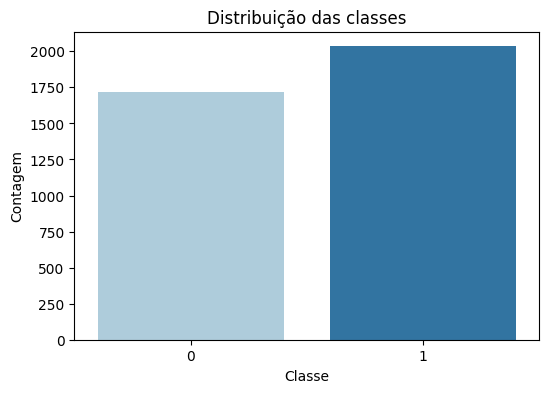

In [12]:
# Distribuição
plt.figure(figsize=(6, 4))
sns.countplot(x=y, palette='Paired', hue=y, legend=False)
plt.title('Distribuição das classes')
plt.xlabel('Classe')
plt.ylabel('Contagem')
plt.show()

Avaliamos o balanceamento da variável alvo e o comportamento da variância explicada através da Análise de Componentes Principais (PCA).

O gráfico de contagem apresenta o número de moléculas em cada classe de `target`. A comparação das alturas das barras permite avaliar visualmente se as classes estão aproximadamente equilibradas ou se uma delas predomina.

A interpretação deve ser baseada nas contagens e proporções efetivamente observadas. Para cada classe (c), a proporção pode ser calculada por

$$
[`\hat `{=tex}p_c=`\frac{n_c}{N}`{=tex},]
$$

em que (n_c) é o número de observações da classe e (N) é o total de moléculas. Recomenda-se informar os valores absolutos e percentuais no texto ou sobre as barras.

Se uma classe for muito mais frequente, um modelo pode obter acurácia aparentemente elevada simplesmente favorecendo a classe majoritária.
Nesse cenário, a avaliação deve dar atenção especial ao *recall*, à precisão, ao F1 e à matriz de confusão. Se as barras forem semelhantes, isso indica equilíbrio marginal da variável-alvo, mas não demonstra que a classificação seja fácil nem que os atributos sejam informativos.



**Limite da figura:** o gráfico descreve apenas a frequência das classes. Ele não mostra quais descritores explicam a resposta nem estabelece uma relação causal entre características químicas e atividade biológica.

In [13]:
scaler = StandardScaler()
X_treino_scaled = scaler.fit_transform(X_treino)
pca = PCA()
pca.fit(X_treino_scaled)
variancia_acumulada = np.cumsum(pca.explained_variance_ratio_)

In [14]:
# 4. Análise de Componentes Principais (PCA) e Variância
# Normalizando os dados antes do PCA, devido à alta dimensionalidade
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_treino)

pca = PCA()
pca.fit(X_treino_scaled)
variancia_explicada = pca.explained_variance_ratio_
variancia_acumulada = np.cumsum(pca.explained_variance_ratio_)

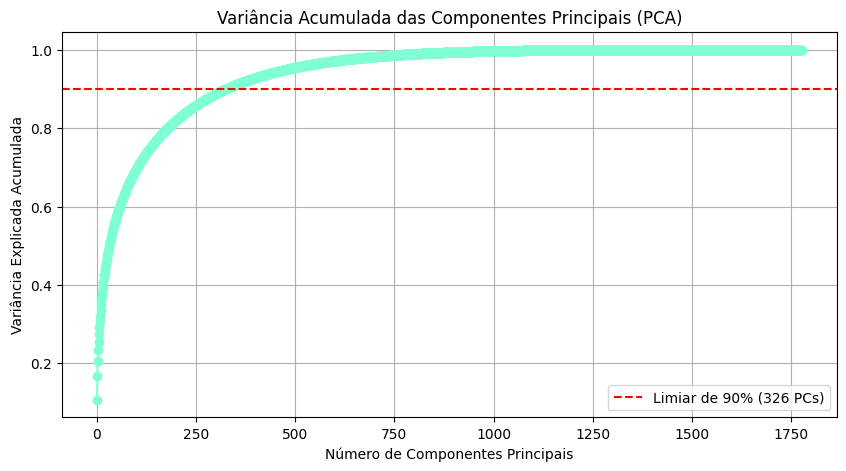


Número de componentes principais necessárias para reter 90% da variância dos dados: 326


In [15]:
# Definindo um limiar de 90% da variância explicada
limiar_variancia = 0.90
n_componentes_90 = np.argmax(variancia_acumulada >= limiar_variancia) + 1

# Gráfico da variância acumulada
plt.figure(figsize=(10, 5))
plt.plot(np.arange(1, len(variancia_acumulada) + 1), variancia_acumulada, marker='o', linestyle='-', color='aquamarine')
plt.axhline(limiar_variancia, linestyle='--', color='red', label=f'Limiar de {int(limiar_variancia*100)}% ({n_componentes_90} PCs)')
plt.title('Variância Acumulada das Componentes Principais (PCA)')
plt.xlabel('Número de Componentes Principais')
plt.ylabel('Variância Explicada Acumulada')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

print(f"\nNúmero de componentes principais necessárias para reter 90% da variância dos dados: {n_componentes_90}")

O eixo horizontal representa o número de componentes incluídos; o eixo vertical representa a fração acumulada da variância dos atributos explicada por esses componentes. A linha horizontal de referência indica o limiar de 90%.

O resultado registrado no notebook indica que **326 componentes principais** são necessários para alcançar 90% da variância acumulada. Em relação aos 1.776 descritores originais, isso corresponde a aproximadamente 18,4% do número inicial de dimensões. Portanto, a representação pode ser reduzida substancialmente em termos de dimensionalidade, preservando 90% da variância total dos atributos segundo o PCA ajustado.

Essa observação sugere que a variância não está concentrada em pouquíssimas direções. Entretanto, não permite concluir que os 326 componentes sejam os melhores preditores da resposta. PCA é uma técnica não supervisionada: ela não utiliza `target` para escolher as direções. Uma componente com variância elevada pode conter pouca informação discriminativa, enquanto uma componente de variância menor pode ser relevante para a classificação.

**Ponto de atenção:** o PCA deve ser ajustado somente com dados de
treinamento. No código acima 0 ajuste é feito em `X_treino_scaled`, o que
evita o uso direto do conjunto de teste nesta etapa exploratória. Para
comparar modelos com e sem PCA, a transformação deve ser inserida no
pipeline e reestimada dentro de cada fold.

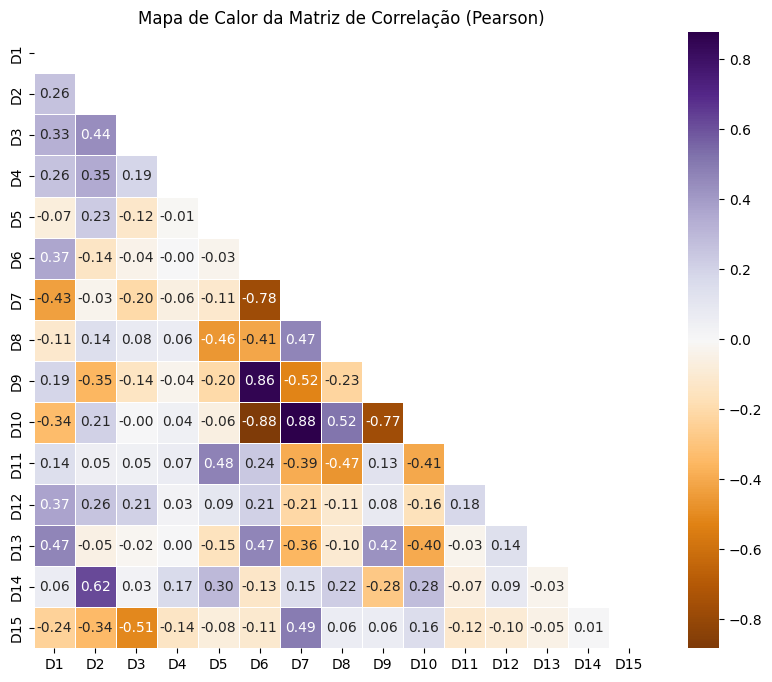

In [16]:
# Matriz de Correlação e Heatmap
amostra_features = X.iloc[:, :15] 
matriz_corr = amostra_features.corr()

plt.figure(figsize=(10, 8))
mascara = np.triu(np.ones_like(matriz_corr, dtype=bool))
mapa_de_cor = sns.diverging_palette(280, 30, s=95, l=40, as_cmap=True)
sns.heatmap(
    matriz_corr,
    mask=mascara,
    cmap="PuOr",
    center=0,
    square=True,
    linewidths=0.5,
    annot=True,
    fmt=".2f"
)
plt.title("Mapa de Calor da Matriz de Correlação (Pearson)")
plt.show()

O mapa de calor representa os coeficientes de correlação linear de Pearson entre pares de atributos. Os valores variam de −1 a +1: valores próximos de +1 indicam associação linear positiva; valores próximos de −1 indicam associação linear negativa; valores próximos de zero indicam ausência de associação linear forte.

A máscara triangular evita exibir duas vezes a mesma informação, pois a matriz de correlação é simétrica. A escala divergente centrada em zero diferencia correlações positivas e negativas, enquanto os valores anotados permitem verificar a magnitude de cada coeficiente.

A figura foi construída apenas com `D1` a `D15`. Por isso, ela é uma **amostra exploratória**, não uma descrição da estrutura de correlação dos 1.776 descritores. Não se deve generalizar o padrão observado nesses 15 atributos para todo o conjunto. Para uma investigação mais abrangente, seria possível selecionar atributos por um critério explícito ou resumir a distribuição das correlações entre todos os pares, considerando o custo computacional e a legibilidade.

Correlação elevada entre atributos pode indicar redundância e afetar a interpretação de modelos lineares. Contudo, correlação não demonstra causalidade e correlação linear baixa não exclui relações não lineares. Além disso, o impacto da multicolinearidade depende do algoritmo: pode
dificultar a interpretação de coeficientes de modelos lineares, enquanto modelos baseados em árvores respondem de maneira diferente.

## Modelos

O notebook vai apresentar os seguintes algoritmos para comparação:

-   Árvore de Decisão;
-   Floresta Aleatória;
-   XGBoost;
-   Regressão Logística;
-   LightGBM.

O `DummyClassifier` estratificado vai ser o *baseline*. O baseline não procura aprender relações químicas; serve para contextualizar o ganho obtido pelos modelos treinados.

Cada algoritmo deve ser otimizado em pelo menos 100 tentativas do
Optuna. A função objetivo utiliza a média da ROC-AUC em validação
cruzada estratificada. Para assegurar uma comparação justa, os
algoritmos devem usar os mesmos folds, e os espaços de busca, número de
tentativas, sementes aleatórias e critérios de seleção devem ser
registrados.

*OBS:* A ``função objetivo`` é uma função matemática usada para maximizar ou minimizar um valor específico em problemas de otimização, como lucro, custo ou produção.

## Modelo Baseline

O `DummyClassifier(strategy="stratified")` gera previsões sem aprender a relação entre os descritores e a resposta, usando as proporções observadas das classes como referência para a estratégia estratificada. Seu papel é estabelecer um patamar mínimo para contextualizar os modelos de aprendizado.

In [17]:
baseline = DummyClassifier(strategy="stratified", random_state=67)
baseline.fit(X_treino, y_treino)

y_pred_base = baseline.predict(X_teste)
y_prob_base = baseline.predict_proba(X_teste)[:, 1]

acc_base = accuracy_score(y_teste, y_pred_base)
auc_base = roc_auc_score(y_teste, y_prob_base)

print(f"Acurácia do Baseline: {acc_base:.4f}")
print(f"ROC-AUC do Baseline:  {auc_base:.4f}")

Acurácia do Baseline: 0.4927
ROC-AUC do Baseline:  0.4883


No resultado registrado, o baseline apresenta acurácia de **0,4993** e ROC-AUC de **0,4953**. A acurácia está próxima de 0,5 e a ROC-AUC está próxima do valor de referência de 0,5, indicando desempenho semelhante ao acaso.

Esse resultado não demonstra que o conjunto de dados não contenha sinal preditivo; indica apenas que o baseline escolhido não o explora. A comparação deve ser feita com os modelos otimizados no mesmo conjunto de teste.

## Otimização de Hiperparâmetros com Optuna

A otimização busca configurações que maximizem a ROC-AUC média na validação cruzada. Cada ponto no histórico de otimização representa uma tentativa, e o valor no eixo vertical corresponde ao resultado da função objetivo para aquela configuração.

A melhor tentativa observada não é necessariamente uma prova de convergência global. Um histórico com melhorias iniciais seguidas de resultados próximos pode sugerir que a busca encontrou uma região promissora; oscilações persistentes podem indicar que configurações
distintas continuam produzindo resultados variados. A interpretação depende do padrão efetivamente exibido e do espaço de busca utilizado.

O número da tentativa no eixo horizontal representa a ordem de avaliação, não uma escala contínua de hiperparâmetros. A linha do histórico pode destacar o melhor valor acumulado ou representar os
valores das tentativas, conforme a função de visualização do Optuna. A legenda e a interpretação devem corresponder ao comportamento real do gráfico.

In [18]:
# Definindo a função objetivo do Optuna
def funcao_objetivo(trial):
    # Espaço de busca para o RandomForestClassifier
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 50, 300, log=True),
        "max_depth": trial.suggest_int("max_depth", 5, 30),
        "min_samples_split": trial.suggest_int("min_samples_split", 2, 10),
        "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 10),
        "max_features": trial.suggest_float("max_features", 0.1, 1.0),
        "random_state": 67,
        "n_jobs": -1,
        "bootstrap": True,
    }
    
    modelo = RandomForestClassifier(**params)
    
    # Validação cruzada estratificada para evitar vazamento e lidar com desbalanceamento
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    
    # Utilizando ROC-AUC como métrica principal de avaliação
    scores = cross_val_score(modelo, X_treino, y_treino, cv=cv, scoring="roc_auc")
    
    return scores.mean()

In [19]:
# Dicionários para armazenar os estudos e os melhores modelos otimizados
estudos = {}
melhores_modelos = {}

Árvore de Decisão

In [20]:
def objective_dt(trial):
    params = {
        "max_depth": trial.suggest_int("max_depth", 2, 30),
        "min_samples_split": trial.suggest_int("min_samples_split", 2, 20),
        "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 20),
        "random_state": 67
    }
    model = DecisionTreeClassifier(**params)
    scores = cross_val_score(model, X_treino, y_treino, cv=cv_stratified, scoring="roc_auc")
    return scores.mean()

study_dt = optuna.create_study(direction="maximize")
study_dt.optimize(objective_dt, n_trials=100)
estudos['Árvore de Decisão'] = study_dt
melhores_modelos['Árvore de Decisão'] = DecisionTreeClassifier(**study_dt.best_params, random_state=67)
print(f"[Árvore de Decisão] Melhor ROC-AUC (CV): {study_dt.best_value:.4f}")

[Árvore de Decisão] Melhor ROC-AUC (CV): 0.8062


Floresta Aleatoria

In [21]:
def objective_rf(trial):
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 50, 250, log=True),
        "max_depth": trial.suggest_int("max_depth", 5, 30),
        "min_samples_split": trial.suggest_int("min_samples_split", 2, 10),
        "max_features": trial.suggest_float("max_features", 0.1, 1.0),
        "random_state": 67,
        "n_jobs": -1
    }
    model = RandomForestClassifier(**params)
    scores = cross_val_score(model, X_treino, y_treino, cv=cv_stratified, scoring="roc_auc")
    return scores.mean()

study_rf = optuna.create_study(direction="maximize")
study_rf.optimize(objective_rf, n_trials=100)
estudos['Random Forest'] = study_rf
melhores_modelos['Random Forest'] = RandomForestClassifier(**study_rf.best_params, random_state=67, n_jobs=-1)
print(f"[Random Forest] Melhor ROC-AUC (CV): {study_rf.best_value:.4f}")

[Random Forest] Melhor ROC-AUC (CV): 0.8702


XGBoost

In [22]:
def objective_xgb(trial):
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 50, 250, log=True),
        "max_depth": trial.suggest_int("max_depth", 3, 10),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
        "subsample": trial.suggest_float("subsample", 0.5, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
        "random_state": 67,
        "n_jobs": -1,
        "eval_metric": "logloss"
    }
    model = XGBClassifier(**params)
    scores = cross_val_score(model, X_treino, y_treino, cv=cv_stratified, scoring="roc_auc")
    return scores.mean()

study_xgb = optuna.create_study(direction="maximize")
study_xgb.optimize(objective_xgb, n_trials=100)
estudos['XGBoost'] = study_xgb
melhores_modelos['XGBoost'] = XGBClassifier(**study_xgb.best_params, random_state=67, n_jobs=-1, eval_metric="logloss")
print(f"[XGBoost] Melhor ROC-AUC (CV): {study_xgb.best_value:.4f}")

[XGBoost] Melhor ROC-AUC (CV): 0.8754


K-Nearest Neighbor(KNN)

In [25]:
def objective_knn(trial):
    params = {
        "n_neighbors": trial.suggest_int("n_neighbors", 1, 50),
        "weights": trial.suggest_categorical("weights", ["uniform", "distance"]),
        "metric": trial.suggest_categorical("metric", ["euclidean", "manhattan", "minkowski"])
    }
    
    model = KNeighborsClassifier(**params)
    
    scores = cross_val_score(model, X_treino_scaled, y_treino, cv=cv_stratified, scoring="roc_auc")
    
    return scores.mean()

study_knn = optuna.create_study(direction="maximize")
study_knn.optimize(objective_knn, n_trials=100)
estudos['knn'] = study_knn
melhores_modelos['knn'] = KNeighborsClassifier(**study_knn.best_params)
print(f"[KNN] Melhor ROC-AUC (CV): {study_knn.best_value:.4f}")

[KNN] Melhor ROC-AUC (CV): 0.8320


LightGBM

In [26]:
def objective_lgb(trial):
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 50, 250, log=True),
        "num_leaves": trial.suggest_int("num_leaves", 20, 150),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
        "subsample": trial.suggest_float("subsample", 0.5, 1.0),
        "random_state": 67,
        "n_jobs": -1,
        "verbose": -1
    }
    model = LGBMClassifier(**params)
    scores = cross_val_score(model, X_treino, y_treino, cv=cv_stratified, scoring="roc_auc")
    return scores.mean()

study_lgb = optuna.create_study(direction="maximize")
study_lgb.optimize(objective_lgb, n_trials=100)
estudos['LightGBM'] = study_lgb
melhores_modelos['LightGBM'] = LGBMClassifier(**study_lgb.best_params, random_state=67, n_jobs=-1, verbose=-1)
print(f"[LightGBM] Melhor ROC-AUC (CV): {study_lgb.best_value:.4f}")

[LightGBM] Melhor ROC-AUC (CV): 0.8691


## Predições, Avaliação e Visualizações

Treinamos os modelos com seus melhores hiperparâmetros em todo o conjunto de treino e geramos as predições no conjunto de teste independente, acompanhadas de novas visualizações gráficas.

In [27]:
# Dicionários para guardar os resultados de teste
resultados_desempenho = []
curvas_roc = {}

# Avaliação do Baseline
resultados_desempenho.append({
    'Modelo': 'Baseline (Estratificado)',
    'Acurácia': acc_base,
    'ROC-AUC': auc_base
})
curvas_roc['Baseline'] = roc_curve(y_teste, y_prob_base)

In [28]:
# Avaliação dos modelos otimizados
for nome, modelo in melhores_modelos.items():
    modelo.fit(X_treino, y_treino)
    y_pred = modelo.predict(X_teste)
    y_prob = modelo.predict_proba(X_teste)[:, 1]
    
    acc = accuracy_score(y_teste, y_pred)
    auc = roc_auc_score(y_teste, y_prob)
    
    resultados_desempenho.append({
        'Modelo': nome,
        'Acurácia': acc,
        'ROC-AUC': auc
    })
    curvas_roc[nome] = roc_curve(y_teste, y_prob)

df_resultados = pd.DataFrame(resultados_desempenho).sort_values(by='ROC-AUC', ascending=False)
print("Tabela de Desempenho no Conjunto de Teste")
print(df_resultados.to_string(index=False))

Tabela de Desempenho no Conjunto de Teste
                  Modelo  Acurácia  ROC-AUC
                 XGBoost  0.804261 0.883385
                LightGBM  0.809587 0.880307
           Random Forest  0.809587 0.872050
                     knn  0.762983 0.848459
       Árvore de Decisão  0.736352 0.811743
Baseline (Estratificado)  0.492676 0.488294


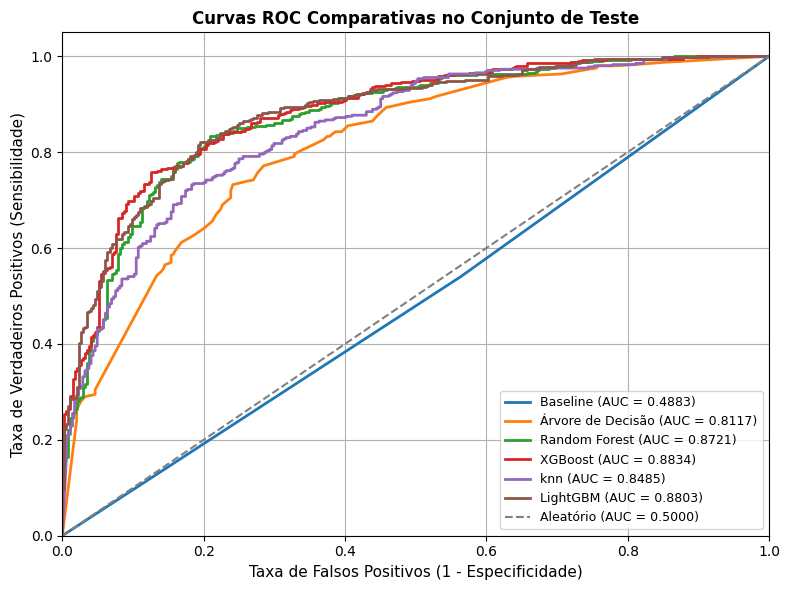

In [30]:
# --- Curvas ROC Comparativas (Corrigido) ---
plt.figure(figsize=(8, 6))

for nome, (fpr, tpr, _) in curvas_roc.items():
    # Padronização da busca
    nome_busca = 'Baseline (Estratificado)' if nome == 'Baseline' else nome
    
    # Filtra caso haja divergência
    match = [r['ROC-AUC'] for r in resultados_desempenho if r['Modelo'] == nome_busca]
    
    if match:
        auc_val = match[0]
        plt.plot(fpr, tpr, lw=2, label=f'{nome} (AUC = {auc_val:.4f})')

plt.plot([0, 1], [0, 1], color='gray', linestyle='--', lw=1.5, label='Aleatório (AUC = 0.5000)')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Taxa de Falsos Positivos (1 - Especificidade)', fontsize=11)
plt.ylabel('Taxa de Verdadeiros Positivos (Sensibilidade)', fontsize=11)
plt.title('Curvas ROC Comparativas no Conjunto de Teste', fontsize=12, fontweight='bold')
plt.legend(loc="lower right", fontsize=9)
plt.grid(True)
plt.tight_layout()
plt.show()

C:\Users\abraham2610048\AppData\Local\Temp\ipykernel_11096\3685271531.py:3: ExperimentalWarning: optuna.visualization.matplotlib._optimization_history.plot_optimization_history is experimental (supported from v2.2.0). The interface can change in the future.
  fig_hist = optuna.visualization.matplotlib.plot_optimization_history(estudos[melhor_nome_estudo])


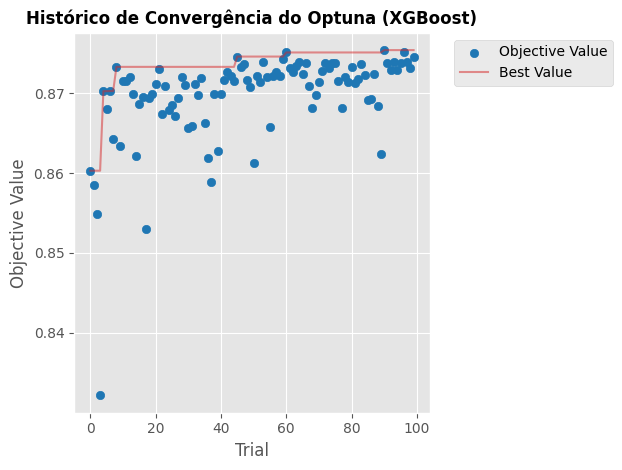

In [31]:
# Histórico de Otimização do Melhor Modelo
melhor_nome_estudo = max(estudos, key=lambda k: estudos[k].best_value)
fig_hist = optuna.visualization.matplotlib.plot_optimization_history(estudos[melhor_nome_estudo])
plt.title(f'Histórico de Convergência do Optuna ({melhor_nome_estudo})', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

## Conclusões e principais aprendizados

O conjunto BioResponse ofereceu um problema de classificação binária de alta dimensionalidade, com 3.751 moléculas descritas por 1.776 atributos numéricos. A inspeção inicial reportada não identificou valores ausentes. A análise por PCA indicou a necessidade de 326 componentes para explicar 90% da variância dos atributos, mostrando que é possível reduzir a dimensionalidade em relação à representação original, embora essa redução não assegure a preservação da informação relevante para a classificação.

O baseline estratificado apresentou acurácia de 0,4993 e ROC-AUC de 0,4953, constituindo uma referência próxima do desempenho aleatório. A conclusão sobre o benefício dos algoritmos treinados depende, contudo, dos resultados finais de teste, das métricas complementares e da
estabilidade entre folds. Como os resultados completos de otimização e teste não estão todos registrados no documento consultado, não é apropriado declarar antecipadamente um algoritmo vencedor.

O principal aprendizado é que a qualidade de um sistema preditivo não deve ser avaliada apenas pela maior pontuação observada. É necessário preservar a independência do teste, evitar vazamento de dados, documentar a busca de hiperparâmetros, combinar métricas
complementares e interpretar as visualizações de acordo com aquilo que efetivamente representam. Em aplicações biológicas, também é essencial distinguir desempenho estatístico de evidência sobre mecanismo ou eficácia biológica.

## Descrição do uso de IA neste trabalho

Ferramentas de inteligência artificial generativa foram utilizadas como
apoio à revisão da redação científica, à organização das seções, à explicação de conceitos matematicos de maneira didatica de aprendizado de máquina e à sugestão de melhorias na apresentação e interpretação das visualizações. As decisões metodológicas, a execução dos códigos, a verificação dos resultados numéricos e a responsabilidade pelas conclusões permanecem a cargo do autor.
A responsabilidade pela realização do trabalho é inteiramente do aluno, a IA foi utilizada para complementação com revisão e adaptação do autor.

## Referências

ZHU, Bingjie; LIAO, Jie; LIU, Huihui; FAN, Xiaohui; CHENG, Yiyu. **MSformer: A Meta-Structure Based Interpretable Framework for Representation Learning of Natural Products**. Analytical Chemistry, v. 97, n. 47, p. 26009–26023, 2025. DOI: [https://doi.org/10.1021/acs.analchem.5c03958](https://doi.org/10.1021/acs.analchem.5c03958).

OPENML. **BioResponse**. Conjunto de dados, ID 4134. Disponível em:
https://www.openml.org/search?type=data&sort=runs&status=active&id=4134.


OPTUNA. **Optuna: A hyperparameter optimization framework**.
Documentação oficial. Disponível em: https://optuna.org/.

SCIKIT-LEARN. **User Guide: Cross-validation; model evaluation;
decomposition**. Documentação oficial. Disponível em:
https://scikit-learn.org/stable/user_guide.html.

SEABORN. **Choosing color palettes**. Documentação oficial. Disponível
em: https://seaborn.pydata.org/tutorial/color_palettes.html.